# 07b · Estrategias, sensibilidad, local/global, semillas y actualización

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "data.py").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Ejecutar desde el repositorio DL-LAB09")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from src import data as D, metrics as M, backtest as B
RUN_TRAIN = False  # Cambiar a True solo para generar artefactos que falten.


Los barridos y la elección del mejor modelo usan validación. El global de 150 clientes se compara con diez modelos locales sobre los mismos diez IDs. Los experimentos de semillas y actualización congelan configuración antes de prueba.

In [2]:
if RUN_TRAIN:
    import subprocess
    subprocess.run([sys.executable,"-m","src.run_cisco","--stage","experiments"],cwd=ROOT,check=True)

In [3]:
exp=ROOT/"outputs"/"runs"/"experimentos_B"
for name in ["sensibilidad.csv","baseline_L.csv","local_global.csv"]:
    display(Markdown(f"### {name}"))
    display(pd.read_csv(exp/name))
display(json.loads((exp/"best_dl_selection.json").read_text()))

### sensibilidad.csv

,modelo,L,meses,val_MAE,val_MASE,train_s,epochs_max,max_batches_per_epoch
0,LSTM_Multi,48,30,86.283928,1.024582,48.319276,15,1000
1,LSTM_Multi,168,30,81.029434,0.988422,201.889232,15,1000
2,LSTM_Multi,336,30,80.581223,1.018776,284.051895,15,1000
3,LSTM_Multi,168,3,136.849014,1.549986,39.485289,15,1000
4,LSTM_Multi,168,12,83.187691,1.004614,201.398081,15,1000


### baseline_L.csv

,modelo,L,L_efectivo,val_MASE,fuente,train_s
0,SeasonalNaive24,48,24,0.985479,A: barrido_historia.csv; invariancia exacta pa...,0.000000
1,SeasonalNaive24,168,24,0.985479,A: barrido_historia.csv; invariancia exacta pa...,0.000000
2,SeasonalNaive24,336,24,0.985479,A: barrido_historia.csv; invariancia exacta pa...,0.000000
3,LightGBM,48,24,0.951847,"B CPU: mismos parámetros de A/historia, sin re...",65.575525
4,LightGBM,168,168,0.857282,"A: barrido_historia.csv; rezagos fijos 1-24,16...",37.143831
5,LightGBM,336,168,0.857282,"A: barrido_historia.csv; rezagos fijos 1-24,16...",37.143831


### local_global.csv

,alcance,MAE,RMSE,WAPE,MAPE,MAPE_excluidas,MASE,n,train_s,params
0,global_150_evaluado_10,88.802770,289.096354,0.056912,0.104126,0,1.040088,22080,201.889232,111768
1,local_10,115.672086,348.134082,0.074132,0.186111,0,1.582074,22080,11.120306,1117680


{'criterio': 'MASE validación, todas las familias A y B',
 'mejor': {'modelo': 'NHITS',
  'hardware': 'NVIDIA GeForce RTX 5070 Laptop GPU',
  'inference_s': 11.983267244999297,
  'familia': 'Convolucionales',
  'L': 168,
  'estrategia': 'multi-salida',
  'covariables': False,
  'params_total': 2817570,
  'params_entrenables': 2817570,
  'train_s': 36.22452499700012,
  'pasos_seleccion': 1500,
  'pasos_final': 1500,
  'val_MASE': 0.7989026611705128,
  'validation_step_size': 24,
  'gpu_mem_pico_MB': 1217.3740234375,
  'MAE': 56.26422083662647,
  'RMSE': 493.82672427611243,
  'WAPE': 0.07199188883560259,
  'MAPE': 0.1048301982687758,
  'MASE': 0.815663903814208,
  'MASE_navidad': 1.5242147343864587},
 'candidatos': [{'modelo': 'NLinear', 'val_MASE': 0.8778082728385925},
  {'modelo': 'DLinear', 'val_MASE': 0.8797428607940674},
  {'modelo': 'MLP', 'val_MASE': 0.8200646042823792},
  {'modelo': 'PatchTST', 'val_MASE': 0.8568459874851447},
  {'modelo': 'iTransformer', 'val_MASE': 0.8079002902

In [4]:
tab=pd.read_csv(ROOT/"outputs"/"tables"/"todos_resultados.csv")
display(tab.loc[tab.familia.isin(["Semillas","Reentrenamiento"])])
seeds=tab.loc[tab.familia=="Semillas"]
display(seeds[["MAE","MASE"]].agg(["mean","std"]))

,modelo,hardware,inference_s,familia,L,estrategia,covariables,train_s,model_id,load_s,...,train_s_search_total,seed,hidden,epochs,max_batches_per_epoch,arboles,seleccion,params_referencia,nota,pasos
0,NHITS_seed7,NVIDIA GeForce RTX 5070 Laptop GPU,12.394872,Semillas,168,multi-salida,False,18.225615,NaN,NaN,...,NaN,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1500.0
1,NHITS_seed123,NVIDIA GeForce RTX 5070 Laptop GPU,12.481867,Semillas,168,multi-salida,False,18.482134,NaN,NaN,...,NaN,123.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1500.0
3,NHITS_mensual,NVIDIA GeForce RTX 5070 Laptop GPU,11.668495,Reentrenamiento,168,mensual expandible,False,56.998578,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1500.0
4,NHITS_seed42,NVIDIA GeForce RTX 5070 Laptop GPU,12.272632,Semillas,168,multi-salida,False,18.055412,NaN,NaN,...,NaN,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1500.0
10,LightGBM_mensual,CPU (AMD Ryzen AI 7 350 w/ Radeon 860M),25.454578,Reentrenamiento,168,mensual expandible,True,270.994094,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,validación; configuración congelada antes de p...,"Conteo del modelo de diciembre, reconstruido c...",NaN,NaN


,MAE,MASE
mean,55.687066,0.807781
std,0.557154,0.006390


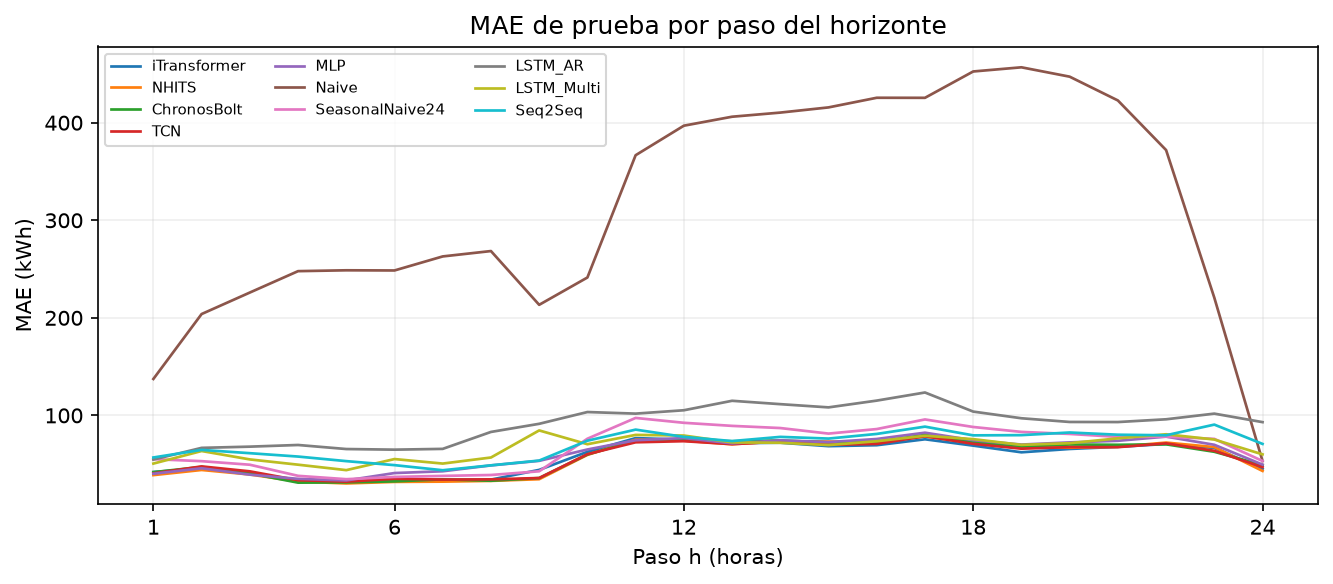

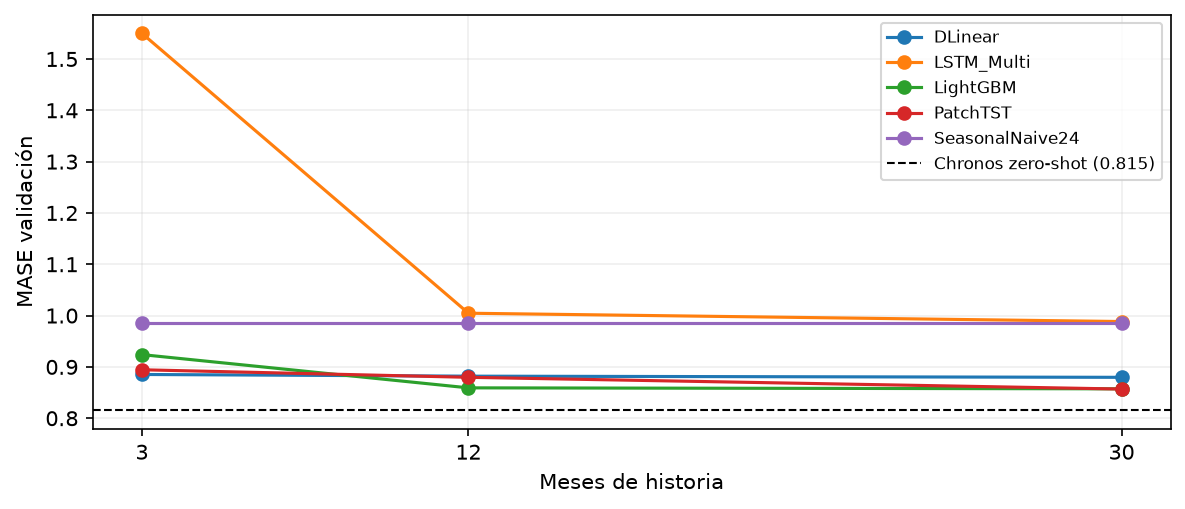

In [5]:
for name in ["mae_por_h","mase_vs_historia"]:
    display(Image(filename=str(ROOT/"outputs"/"figs"/f"{name}.png")))